In [46]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

data = pd.read_csv('uber.csv')
print(data.head())


   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565         40.772647                1  
3         

In [47]:
print(data.info())
print(data.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  str    
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  str    
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), str(2)
memory usage: 13.7 MB
None
Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64


In [48]:
print(data.isnull().sum())

Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64


In [49]:

data = data.dropna()
data = data[data['fare_amount'] > 0]
data['pickup_datetime'] = pd.to_datetime(data['pickup_datetime'])
data['hour'] = data['pickup_datetime'].dt.hour
data['day_of_week'] = data['pickup_datetime'].dt.dayofweek
# Prix
data = data[(data['fare_amount'] > 0) & (data['fare_amount'] < 100)]


# Passagers
data = data[(data['passenger_count'] > 0) & (data['passenger_count'] <= 6)]
print("Après filtre passagers :", len(data))


print("Doublons :", data.duplicated().sum())
data = data.drop_duplicates()




Après filtre passagers : 199178
Doublons : 0


In [50]:

data = data[
    data['pickup_latitude'].between(40, 42) &
    data['dropoff_latitude'].between(40, 42) &
    data['pickup_longitude'].between(-75, -72) &
    data['dropoff_longitude'].between(-75, -72)
]

print("Après filtre coordonnées :", len(data))

print(data.describe())


Après filtre coordonnées : 199166
         Unnamed: 0    fare_amount  pickup_longitude  pickup_latitude  \
count  1.991660e+05  199166.000000     199166.000000    199166.000000   
mean   2.771572e+07      11.310396        -72.506132        39.920228   
std    1.601415e+07       9.433859         10.435712         6.124546   
min    1.000000e+00       0.010000        -93.824668       -74.015515   
25%    1.382642e+07       6.000000        -73.992064        40.734804   
50%    2.775597e+07       8.500000        -73.981828        40.752584   
75%    4.156007e+07      12.500000        -73.967177        40.767151   
max    5.542357e+07      99.200000         40.808425        48.018760   

       dropoff_longitude  dropoff_latitude  passenger_count           hour  \
count      199166.000000     199166.000000    199166.000000  199166.000000   
mean          -72.516351         39.924512         1.689576      13.493588   
std            10.396465          6.111078         1.305517       6.515593

In [51]:
#calcule la distance

def haversine(lat1, lon1, lat2, lon2):
    R = 6371
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2-lat1)/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin((lon2-lon1)/2)**2
    return 2 * R * np.arcsin(np.sqrt(a))

data['distance'] = haversine(data['pickup_latitude'], data['pickup_longitude'],
                             data['dropoff_latitude'], data['dropoff_longitude'])


In [52]:
data = data[(data['distance'] > 0.1) & (data['distance'] < 100)]
data = data[data['fare_amount'] < 100]

In [53]:
from sklearn.model_selection import train_test_split
X = data[['distance', 'hour', 'day_of_week']]
y = data['fare_amount']                          # 'fare' -> 'fare_amount'
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [54]:
from sklearn.linear_model import LinearRegression
lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred = lr.predict(X_test)

In [55]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)
print('MAE =', mae)
print('RMSE =', rmse)
print('R² =', r2)

MAE = 2.3304620996750276
RMSE = 4.718095853707658
R² = 0.7463013396112013


In [60]:
from sklearn.ensemble import RandomForestRegressor
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

for nom, modele in [('Linéaire', lr), ('Random Forest', rf)]:
    p = modele.predict(X_test)
    print(nom,
          '| MAE =', round(mean_absolute_error(y_test, p), 3),
          '| RMSE =', round(np.sqrt(mean_squared_error(y_test, p)), 3),
          '| R² test =', round(r2_score(y_test, p), 3),
          '| R² train =', round(modele.score(X_train, y_train), 3))

Linéaire | MAE = 2.33 | RMSE = 4.718 | R² test = 0.746 | R² train = 0.765
Random Forest | MAE = 2.426 | RMSE = 4.264 | R² test = 0.793 | R² train = 0.971


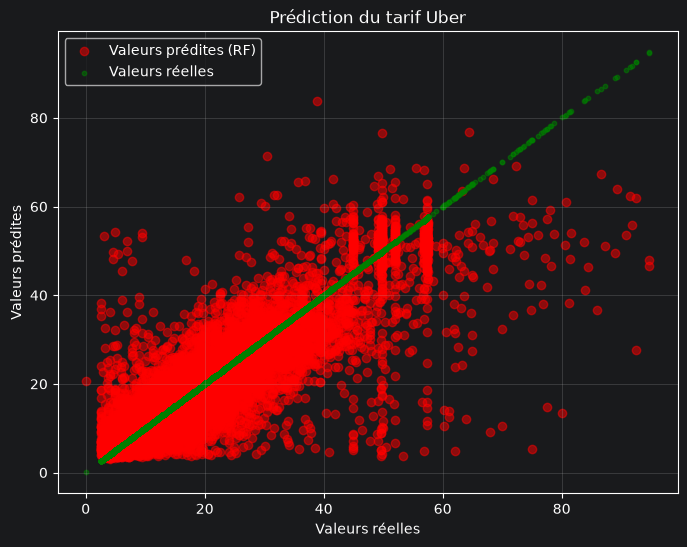

In [57]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_rf, alpha=0.5, color='red', label='Valeurs prédites (RF)')
plt.scatter(y_test, y_test, alpha=0.5, color='green', s=10, label='Valeurs réelles')
plt.xlabel('Valeurs réelles')
plt.ylabel('Valeurs prédites')
plt.title('Prédiction du tarif Uber')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

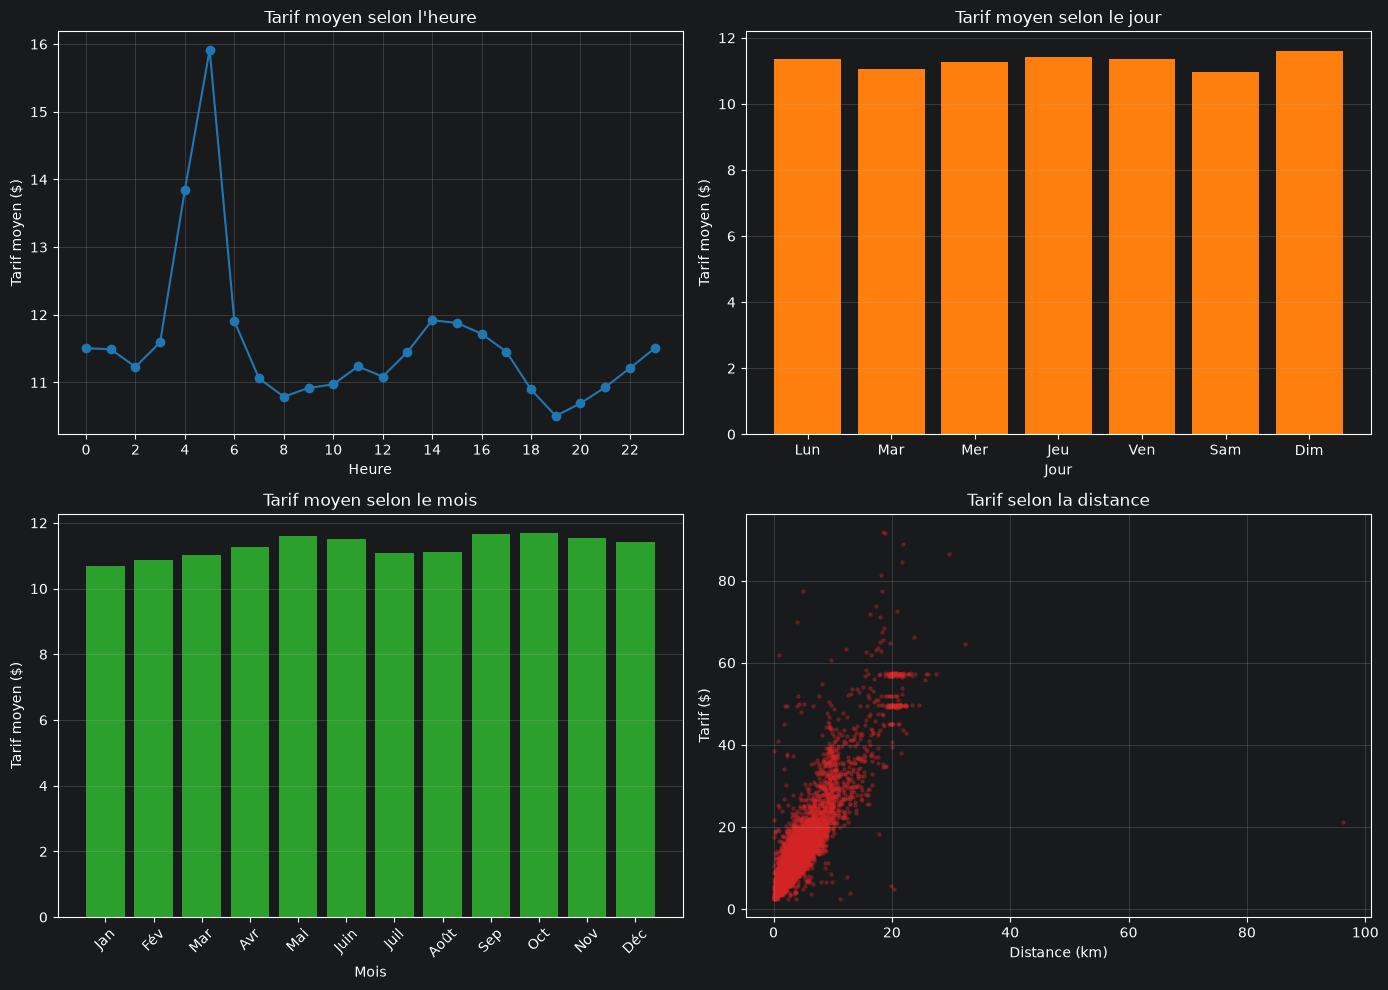

In [58]:
import matplotlib.pyplot as plt
import numpy as np

# Variables temporelles
data['month'] = data['pickup_datetime'].dt.month

jours = ['Lun', 'Mar', 'Mer', 'Jeu', 'Ven', 'Sam', 'Dim']
mois = ['Jan', 'Fév', 'Mar', 'Avr', 'Mai', 'Juin', 'Juil', 'Août', 'Sep', 'Oct', 'Nov', 'Déc']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

#  Tarif moyen selon l'heure
par_heure = data.groupby('hour')['fare_amount'].mean()
axes[0, 0].plot(par_heure.index, par_heure.values, marker='o', color='tab:blue')
axes[0, 0].set_title("Tarif moyen selon l'heure")
axes[0, 0].set_xlabel('Heure')
axes[0, 0].set_ylabel('Tarif moyen ($)')
axes[0, 0].set_xticks(range(0, 24, 2))
axes[0, 0].grid(alpha=0.3)

#  Tarif moyen selon le jour de la semaine
par_jour = data.groupby('day_of_week')['fare_amount'].mean().reindex(range(7))
axes[0, 1].bar(jours, par_jour.values, color='tab:orange')
axes[0, 1].set_title('Tarif moyen selon le jour')
axes[0, 1].set_xlabel('Jour')
axes[0, 1].set_ylabel('Tarif moyen ($)')
axes[0, 1].grid(axis='y', alpha=0.3)

#  Tarif moyen selon le mois
par_mois = data.groupby('month')['fare_amount'].mean().reindex(range(1, 13))
axes[1, 0].bar(mois, par_mois.values, color='tab:green')
axes[1, 0].set_title('Tarif moyen selon le mois')
axes[1, 0].set_xlabel('Mois')
axes[1, 0].set_ylabel('Tarif moyen ($)')
axes[1, 0].tick_params(axis='x', rotation=45)
axes[1, 0].grid(axis='y', alpha=0.3)

# Tarif selon la distance
echantillon = data.sample(n=min(10000, len(data)), random_state=42)
axes[1, 1].scatter(echantillon['distance'], echantillon['fare_amount'], alpha=0.3, s=5, color='tab:red')
axes[1, 1].set_title('Tarif selon la distance')
axes[1, 1].set_xlabel('Distance (km)')
axes[1, 1].set_ylabel('Tarif ($)')
axes[1, 1].grid(alpha=0.3)

plt.tight_layout()
plt.show()